# 파일과 예외

**이 노트북에서 할 일**

1. 주문 두 줄을 파일에 쓰고 다시 읽어, 상품 이름과 정수 수량으로 나눕니다.
2. 없는 파일과 숫자가 아닌 수량에서 나는 오류를 `try`와 `except`로 받아 메시지를 읽습니다.
3. 모든 오류를 빈 목록으로 바꾸는 함수가 두 문제를 감추는 장면을 보고, 파일 없음만 받도록 고칩니다.

**준비물** — API 키 불필요. 데이터 파일은 노트북이 임시 폴더에 직접 만듭니다.
모델 호출은 0번이고 비용은 들지 않습니다. 실행 시간은 1분 이내입니다.

**강의와 실습 범위** — 강의 시간에는 2~5번과 7~10번 소제목을 설명합니다. 6번(값 바꿔 보기)의 비교는 실습 시간에 읽습니다.
강의에서도 6번의 코드 셀 두 개는 실행해 둡니다. 10번 After가 6번에서 바꾼 파일을 읽기 때문입니다.

1~4절과 같은 실습 폴더 `labs/part1/ch02-python`의 `.venv`를 커널로 고릅니다.
이전 커널의 변수는 쓰지 않으므로 첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

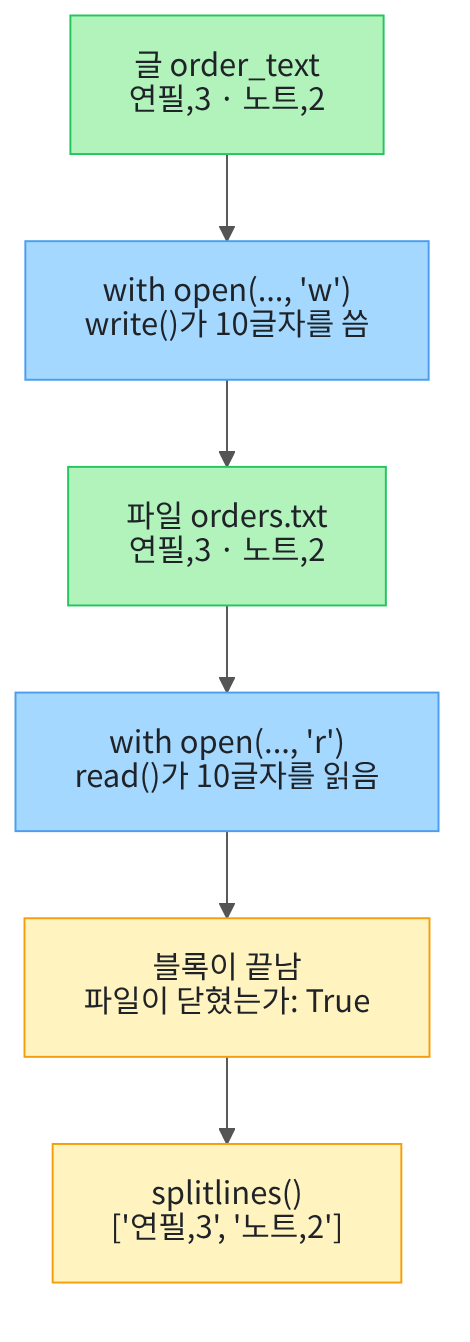

위에서 아래로 읽습니다. 초록 상자는 글과 파일, 파란 상자는 우리가 적은 `with` 블록, 노란 상자는 출력입니다.

쓰기 블록이 글 10글자를 파일 orders.txt에 저장합니다. 읽기 블록이 같은 10글자를 읽고, 블록이 끝나면 파일이 닫힙니다.
맨 아래 노란 상자는 글을 줄마다 나눈 목록입니다.

## 1. 준비

이 절도 설치할 패키지가 없습니다. 이 노트북은 파일을 만들므로, 파일을 둘 빈 폴더를 먼저 준비합니다.

준비 셀은 운영체제의 임시 폴더 안에 새 폴더를 만듭니다. 그리고 그 폴더를 현재 작업 폴더로 옮깁니다.
Ch 1 2절 터미널에서 `cd`로 폴더를 옮긴 것과 같은 일입니다.
그래서 뒤 셀의 파일 이름 `"orders.txt"`는 이 새 폴더 안의 파일을 가리킵니다. 실습 폴더에는 파일이 생기지 않습니다.

코드의 `import` 줄은 1절 준비 셀처럼 Python에 들어 있는 기능 묶음을 불러오는 줄입니다. 자세한 뜻은 7절 모듈과 타입힌트에서 배웁니다.

In [1]:
# 실습 파일을 둘 빈 임시 폴더를 만들고, 그 폴더로 작업 위치를 옮깁니다
import os
import tempfile

# mkdtemp()는 운영체제 임시 폴더 안에 새 폴더를 만들고 그 경로를 반환합니다
practice_folder = tempfile.mkdtemp(prefix="ch02-05-")
# chdir()는 터미널의 cd처럼 현재 작업 폴더를 옮깁니다
os.chdir(practice_folder)
# listdir()는 현재 작업 폴더 안의 파일 이름 목록을 반환합니다
file_names = os.listdir()
# 파일이 생기는 곳을 찾아볼 수 있게 작업 폴더 경로도 출력합니다
print("작업 폴더:", practice_folder)
print("현재 작업 폴더의 파일:", file_names)

작업 폴더: [사용자 폴더]/tmp/ch02-05-lgxzsts5
현재 작업 폴더의 파일: []


**결과 읽기** — 현재 작업 폴더의 파일은 `[]`로, 빈 폴더에서 시작합니다.
작업 폴더 경로는 `ch02-05-` 뒤에 붙은 글자가 실행할 때마다 달라집니다. 운영체제마다 앞부분도 다릅니다.
출력의 `[사용자 폴더]`는 교재를 실행한 컴퓨터의 사용자 폴더 경로를 가린 표시입니다.
준비 셀은 실행할 때마다 새 임시 폴더를 만들고, 앞에서 만든 폴더는 지우지 않습니다.

## 2. 파일에 글 쓰기

파일(file)은 글이나 값을 이름을 붙여 컴퓨터에 저장해 둔 것입니다. 공책에 적어 두면 다음 날에도 읽을 수 있는 것과 같습니다.

변수의 값은 커널을 다시 시작하면 사라집니다. 1~4절이 준비 셀에서 값을 다시 저장한 이유입니다. 파일에 쓴 글은 커널을 다시 시작해도 남습니다.
다만 이 노트북은 준비 셀을 실행할 때마다 새 임시 폴더로 옮깁니다. 앞에서 쓴 파일은 준비 셀이 출력한 앞 폴더에 남아 있습니다.

내장 함수 `open()`은 파일 이름과 모드를 받아 파일을 엽니다. 쓰기 모드 `"w"`는 파일이 없으면 새로 만듭니다. 파일이 있으면 내용을 지우고 새로 씁니다.
문자 인코딩(character encoding)은 글자를 파일에 저장할 숫자로 바꾸는 규칙입니다. 이 절은 쓸 때와 읽을 때 모두 UTF-8 규칙을 씁니다.

`encoding="utf-8"`처럼 매개변수 이름과 값을 등호로 이어 넣는 인자를 키워드 인자(keyword argument)라고 합니다.
정의 줄의 `quantity=1`은 기본값을 정하는 자리이고, 호출 괄호 안의 `encoding="utf-8"`은 값을 이름으로 넣는 자리입니다.
등호 모양은 같지만 적는 곳이 다릅니다. 함수 `open()`의 정의에 기본값이 있는 매개변수 `encoding`이 있어서, 호출할 때 이름으로 값을 넣었습니다.

키워드 인자는 순서가 아니라 이름으로 매개변수를 찾아 들어갑니다. 준비 셀의 `prefix="ch02-05-"`도 키워드 인자였습니다.

예약어 `with`로 시작하는 블록은 파일을 열어 둔 채 들여 쓴 줄을 실행합니다. 블록이 끝나면 파일을 닫습니다.
줄 끝의 `as file`은 열린 파일에 이름 `file`을 붙입니다. 메서드 `write()`는 글을 파일에 쓰고, 쓴 글자 수를 반환합니다.
주문 두 줄은 Ch 1 4절에서 본 여러 줄 글 `"""…"""`로 적습니다.

실행 전에 예상합니다. 「연필,3」은 4글자이고 줄바꿈도 한 글자로 셉니다. 그래서 쓴 글자 수는 10일 것입니다.

In [2]:
# 주문 두 줄을 파일 orders.txt에 UTF-8로 저장합니다
order_text = """연필,3
노트,2
"""
# "w"는 쓰기 모드입니다. 파일이 없으면 새로 만듭니다
with open("orders.txt", "w", encoding="utf-8") as file:
    # write()는 글을 파일에 쓰고, 쓴 글자 수를 반환합니다
    written_count = file.write(order_text)
print("쓴 글자 수:", written_count)

쓴 글자 수: 10


**결과 읽기** — 쓴 글자 수는 `10`으로 예상과 같습니다. 한 줄에 4글자와 줄바꿈 1글자가 두 번입니다.
이 셀은 현재 작업 폴더에 파일 orders.txt를 만들었습니다. 파일이 제대로 저장됐는지는 다음 셀에서 읽어 확인합니다.

## 3. 파일에서 글 읽기

같은 파일을 이번에는 읽기 모드 `"r"`로 엽니다. 읽기 모드는 파일 내용을 바꾸지 않습니다.
메서드 `read()`는 파일의 글 전체를 문자열 하나로 반환합니다.

블록이 끝난 뒤에는 `file.closed` 값으로 파일이 닫혔는지 확인합니다. 점 뒤에 괄호 없이 적는 이 값은 파일이 닫혔으면 `True`입니다.

실행 전에 예상합니다. 읽은 글자 수는 쓴 글자 수와 같은 10이고, 파일이 닫혔는가는 `True`일 것입니다.

In [3]:
# orders.txt를 읽기 모드로 열어 글 전체를 읽습니다
with open("orders.txt", "r", encoding="utf-8") as file:
    # read()는 파일의 글 전체를 문자열 하나로 반환합니다
    text = file.read()
# with 블록이 끝난 뒤의 줄입니다. 파일이 닫혔는지 확인합니다
is_closed = file.closed
text_length = len(text)
print("읽은 글자 수:", text_length)
print("파일이 닫혔는가:", is_closed)
print(text)

읽은 글자 수: 10
파일이 닫혔는가: True
연필,3
노트,2



**결과 읽기** — 읽은 글자 수 `10`, 파일이 닫혔는가 `True`로 예상과 같습니다. 마지막 두 줄에 저장한 글 `연필,3`과 `노트,2`가 그대로 나왔습니다.

파일을 닫는 줄을 따로 적지 않았지만, `with` 블록이 끝날 때 파일이 닫혔습니다. 한글 「연필」도 UTF-8로 쓰고 UTF-8로 읽어 그대로 나왔습니다.

## 4. 파일을 줄 목록으로 읽는 함수

4절처럼 자주 하는 처리에 이름을 붙입니다. 함수 `read_items()`는 파일 이름을 받아 파일의 줄 목록을 반환합니다.
메서드 `splitlines()`는 글을 줄바꿈 자리에서 나눠 문자열 목록을 반환합니다. 줄바꿈 글자는 목록에 넣지 않습니다.

4절처럼 정의 셀과 호출 셀을 나눕니다. 실행 전에 예상합니다. 정의 셀이라 출력은 없을 것입니다.

In [4]:
# 파일 이름을 받아 파일의 줄 목록을 반환하는 함수를 정의합니다
def read_items(file_name):
    with open(file_name, "r", encoding="utf-8") as file:
        text = file.read()
    # splitlines()는 줄바꿈 자리에서 글을 나눠 문자열 목록을 반환합니다
    lines = text.splitlines()
    return lines

**결과 읽기** — 예상대로 출력이 없습니다. 본문의 `with` 블록은 함수를 호출할 때 실행됩니다.

방금 저장한 파일 이름 `"orders.txt"`를 인자로 넣어 함수를 부릅니다.

실행 전에 예상합니다. 줄 목록에는 문자열 두 개 「연필,3」과 「노트,2」가 들고, 줄 수는 2일 것입니다.

In [5]:
# 방금 저장한 파일을 함수로 읽어 줄 목록을 받습니다
items = read_items("orders.txt")
item_count = len(items)
print("줄 목록:", items)
print("줄 수:", item_count)

줄 목록: ['연필,3', '노트,2']
줄 수: 2


**결과 읽기** — 줄 목록은 `['연필,3', '노트,2']`, 줄 수는 `2`로 예상과 같습니다.
글 끝의 줄바꿈 뒤에는 글자가 없어서, 빈 문자열 항목은 생기지 않았습니다.

## 5. 한 줄을 상품 이름과 수량으로 나누기

파일에서 읽은 줄은 모두 문자열입니다. 줄 「연필,3」의 3도 숫자가 아니라 글자입니다.
1절 Before에서 문자열 `"2"`에 3을 곱해 222가 나온 것과 같은 상황입니다.

함수 `parse_order()`는 줄 하나를 받아 (상품 이름, 수량) 튜플을 반환합니다. 메서드 `split(",")`는 글을 쉼표 자리에서 나눠 목록을 반환합니다.
나눈 값 두 개는 3절에서 튜플을 풀어 담은 것처럼 이름 두 개에 차례로 담습니다. 목록도 같은 방법으로 풀어 담을 수 있습니다.
수량 글자는 1절의 `int()`로 정수로 바꿉니다.

실행 전에 예상합니다. 정의 셀이라 출력은 없을 것입니다.

In [6]:
# 주문 한 줄을 받아 (상품 이름, 수량) 튜플을 반환하는 함수를 정의합니다
def parse_order(line):
    # split(",")는 쉼표 자리에서 글을 나눠 목록을 반환합니다
    name, count_text = line.split(",")
    # 파일에서 읽은 수량은 문자열이라 int()로 정수로 바꿉니다
    count = int(count_text)
    order_line = (name, count)
    return order_line

**결과 읽기** — 출력이 없습니다. 정의 셀은 함수 이름과 본문을 기억해 둡니다.

줄 목록의 줄마다 함수를 불러, 4절에서 결제 금액을 모은 모양대로 빈 목록에 모읍니다.
마지막 줄의 검사 줄 `assert`로 첫 주문을 확인합니다.

실행 전에 예상합니다. 주문은 연필 3개와 노트 2개이고, 수량에는 따옴표가 없을 것입니다.

In [7]:
# 줄마다 함수를 불러 주문 튜플을 빈 목록에 모읍니다
orders = []
for line in items:
    order_line = parse_order(line)
    orders.append(order_line)
print("주문 목록:", orders)
# 첫 주문이 연필 3개가 아니면 이 줄에서 멈춥니다
assert orders[0] == ("연필", 3)

주문 목록: [('연필', 3), ('노트', 2)]


**결과 읽기** — 주문 목록은 `[('연필', 3), ('노트', 2)]`로 예상과 같습니다. 검사 줄 `assert`에서도 멈추지 않았습니다.

상품 이름 `'연필'`에는 따옴표가 있고, 수량 3에는 따옴표가 없습니다. 파일의 글자 3이 정수 3으로 바뀌었습니다.

## 6. 값 바꿔 보기 — 파일의 수량 하나만 바꾸기

함수 두 개는 그대로 두고, 파일 첫 줄의 수량만 3에서 5로 바꿉니다. 같은 파일 이름에 쓰기 모드 `"w"`로 다시 씁니다.

실행 전에 예상합니다. 글자 수는 그대로라서 다시 쓴 글자 수도 10일 것입니다.

In [8]:
# 첫 줄의 수량만 3에서 5로 바꾼 글을 같은 파일 이름으로 다시 씁니다
new_order_text = """연필,5
노트,2
"""
# "w" 모드는 있던 내용을 지우고 새로 씁니다
with open("orders.txt", "w", encoding="utf-8") as file:
    written_count = file.write(new_order_text)
print("다시 쓴 글자 수:", written_count)

다시 쓴 글자 수: 10


**결과 읽기** — 다시 쓴 글자 수는 `10`입니다. 숫자 3이 5로 바뀌었을 뿐 글자 수는 같습니다.

같은 두 함수로 파일을 다시 읽어 주문 목록을 만들고, 바꾸기 전 목록 `orders`와 나란히 출력합니다.

실행 전에 예상합니다. 첫 주문만 연필 5개로 바뀔 것입니다. 쓰기 모드는 내용을 지우고 쓰므로 줄 수는 4가 아니라 2일 것입니다.

In [9]:
# 같은 두 함수로 파일을 다시 읽어 주문 목록을 만듭니다
new_items = read_items("orders.txt")
new_orders = []
for line in new_items:
    order_line = parse_order(line)
    new_orders.append(order_line)
new_item_count = len(new_items)
print("바꾸기 전 주문 목록:", orders)
print("바꾼 뒤 주문 목록:", new_orders)
print("바꾼 뒤 줄 수:", new_item_count)

바꾸기 전 주문 목록: [('연필', 3), ('노트', 2)]
바꾼 뒤 주문 목록: [('연필', 5), ('노트', 2)]
바꾼 뒤 줄 수: 2


**결과 읽기** — 바꾼 뒤 주문 목록은 `[('연필', 5), ('노트', 2)]`, 줄 수는 `2`로 예상과 같습니다. 바꾸기 전 목록 `[('연필', 3), ('노트', 2)]`과 첫 주문의 수량만 다릅니다.

바꾼 값은 파일의 수량 하나뿐이고 함수는 그대로입니다. 그래서 출력의 차이는 파일 내용에서 나왔습니다.

## 7. 없는 파일 읽기 — 예외 받기

예외(exception)는 실행 중에 문제가 생겼을 때 Python이 만드는 오류 값입니다.
주문서 봉투를 가지러 갔는데 봉투가 없으면, 직원이 「봉투 없음」을 알리는 것과 같습니다.
2절의 `IndexError`와 3절의 `TypeError`도 예외였습니다. 두 절의 「원리 더 알아보기」는 오류 이름만 보고 문법을 이 절로 미뤘습니다.

예약어 `try` 아래에는 오류가 날 수 있는 줄을 들여 씁니다. 그 아래 `except 오류이름:` 줄에는 그 이름의 오류가 났을 때 실행할 줄을 들여 씁니다.
try 블록에서 오류가 나면 남은 줄은 건너뛰고 except 블록으로 넘어갑니다.
줄 끝의 `as error`는 받은 오류에 이름 `error`를 붙입니다. 이 이름을 출력하면 오류 메시지가 나옵니다.

오류 이름 `FileNotFoundError`는 요청한 파일이 없을 때 나는 오류입니다. 아래 셀은 만들지 않은 파일 `missing.txt`를 읽습니다.
try 없이 읽으면 셀은 오류 메시지를 보이고 그 줄에서 멈춥니다. 노트북을 끝까지 실행하려고 그 장면은 실행하지 않았습니다.

실행 전에 예상합니다. 「읽은 줄 목록」 줄은 출력되지 않고, except 블록의 두 줄과 셀의 마지막 줄이 출력될 것입니다.

In [10]:
# 만들지 않은 missing.txt를 읽어 보고, 파일이 없다는 오류만 받습니다
try:
    missing_items = read_items("missing.txt")
    print("읽은 줄 목록:", missing_items)
except FileNotFoundError as error:
    # 이 블록은 FileNotFoundError가 났을 때만 실행됩니다
    print("FileNotFoundError를 받았습니다")
    print("오류 메시지:", error)
print("셀의 마지막 줄까지 실행했습니다")

FileNotFoundError를 받았습니다
오류 메시지: [Errno 2] No such file or directory: 'missing.txt'
셀의 마지막 줄까지 실행했습니다


**결과 읽기** — 첫 줄 `FileNotFoundError를 받았습니다`는 except 블록이 출력했습니다. 오류 메시지는 `[Errno 2] No such file or directory: 'missing.txt'`입니다. 「읽은 줄 목록」 줄은 출력되지 않았습니다.

오류 메시지는 missing.txt라는 파일이 없다는 뜻입니다. try 블록의 `read_items()` 호출에서 오류가 나서 그 아래 출력 줄을 건너뛰었습니다.
마지막 줄 `셀의 마지막 줄까지 실행했습니다`도 나왔으므로 셀은 멈추지 않았습니다.

## 8. 수량이 숫자가 아닌 줄 — ValueError 받기

1절에서는 숫자 모양이 아닌 문자열을 `int()`에 넣는 장면을 이 절로 미뤘습니다.
이번에는 수량 자리에 글자 「많이」가 든 줄 「연필,많이」를 함수 `parse_order()`에 넣습니다.
오류 이름 `ValueError`는 자료형은 맞지만 값의 모양이 맞지 않을 때 나는 오류입니다. 이번 except 줄에는 이 이름을 적습니다.

실행 전에 예상합니다. 함수 안의 `int()` 줄에서 오류가 나고, except 블록이 오류 메시지를 출력할 것입니다.

In [11]:
# 수량 자리에 숫자가 아닌 글자가 든 줄을 나눠 보고, 값 오류만 받습니다
bad_line = "연필,많이"
try:
    bad_order = parse_order(bad_line)
    print("주문 튜플:", bad_order)
except ValueError as error:
    print("ValueError를 받았습니다")
    print("오류 메시지:", error)

ValueError를 받았습니다
오류 메시지: invalid literal for int() with base 10: '많이'


**결과 읽기** — `ValueError를 받았습니다`가 출력됐고, 오류 메시지는 `invalid literal for int() with base 10: '많이'`입니다. 「주문 튜플」 줄은 출력되지 않았습니다.

메시지는 `int()`가 10진수 정수로 읽을 수 없는 글자 '많이'를 받았다는 뜻입니다.
오류는 함수 `parse_order()` 안의 `int()` 줄에서 났습니다. 그 오류를 함수를 부른 셀의 except 블록이 받았습니다.

## 9. Before — 모든 오류를 빈 목록으로 바꾸기

주문 파일을 읽어 주문 목록을 반환하는 함수를 만듭니다. 파일이 없으면 주문이 0건이라고 보고 빈 목록을 반환하려고 합니다.

먼저 수량 자리에 「많이」가 들어간 주문 파일 `bad_orders.txt`를 하나 더 만듭니다. 둘째 줄 「노트,2」는 정상입니다.

실행 전에 예상합니다. 이 파일의 줄 목록은 「연필,많이」와 「노트,2」 두 줄일 것입니다.

In [12]:
# 수량 자리에 글자가 잘못 들어간 주문 파일을 하나 더 만듭니다
bad_order_text = """연필,많이
노트,2
"""
with open("bad_orders.txt", "w", encoding="utf-8") as file:
    file.write(bad_order_text)
bad_items = read_items("bad_orders.txt")
print("bad_orders.txt 줄 목록:", bad_items)

bad_orders.txt 줄 목록: ['연필,많이', '노트,2']


**결과 읽기** — 줄 목록은 `['연필,많이', '노트,2']`로 예상과 같습니다. 첫 줄의 수량 자리에만 글자가 들어 있습니다.

함수 `load_orders_before()`는 파일을 읽고 줄마다 `parse_order()`를 부릅니다. try 블록에서 오류가 나면 except 블록이 빈 목록을 담습니다.
except 줄에 적은 `Exception`은 거의 모든 오류를 묶어 부르는 이름입니다. 그래서 `FileNotFoundError`와 `ValueError`를 모두 받습니다.

실행 전에 예상합니다. 정의 셀이라 출력은 없을 것입니다.

In [13]:
# 파일의 주문 목록을 반환합니다(어떤 오류가 나도 빈 목록)
def load_orders_before(file_name):
    orders = []
    try:
        lines = read_items(file_name)
        for line in lines:
            order_line = parse_order(line)
            orders.append(order_line)
    except Exception:
        # 어떤 오류든 받아서 주문 0건으로 처리합니다
        orders = []
    return orders

**결과 읽기** — 출력이 없습니다. 이번 정의는 except 줄에 오류 이름 `Exception`을 적었습니다.

없는 파일 `missing.txt`와 수량이 잘못된 파일 `bad_orders.txt`를 같은 함수로 읽습니다. 두 결과가 같은지는 연산자 `==`로 비교합니다.

실행 전에 예상해 봅니다. 두 파일의 문제는 서로 다릅니다. 결과에서 그 차이가 보일까요?

In [14]:
# 없는 파일과 수량이 잘못된 파일을 같은 함수로 읽습니다
missing_orders = load_orders_before("missing.txt")
bad_orders = load_orders_before("bad_orders.txt")
is_same_result = missing_orders == bad_orders
print("missing.txt 주문 목록:", missing_orders)
print("bad_orders.txt 주문 목록:", bad_orders)
print("두 결과가 같은가:", is_same_result)

missing.txt 주문 목록: []
bad_orders.txt 주문 목록: []
두 결과가 같은가: True


**결과 읽기** — missing.txt 주문 목록은 `[]`, bad_orders.txt 주문 목록도 `[]`입니다. 두 결과가 같은가는 `True`입니다.

오류 메시지는 나오지 않았지만, 서로 다른 두 문제가 같은 빈 목록이 되어 구분할 수 없습니다.
bad_orders.txt에는 정상 줄 「노트,2」도 있었는데 함께 사라졌습니다. 1~4절처럼 실행이 멈추지 않아도 결과는 틀릴 수 있습니다.

## 10. After — 파일 없음만 받기

Before 함수와 달라진 곳은 except 줄 하나입니다. 오류 이름을 `Exception`에서 `FileNotFoundError`로 바꿨습니다. 함수 이름은 `load_orders()`로 바꿨습니다.
이제 파일이 없을 때만 빈 목록을 담습니다. 이름이 다른 오류는 받지 않으므로, 함수를 부른 곳으로 그대로 나갑니다.

실행 전에 예상합니다. 정의 셀이라 출력은 없을 것입니다.

In [15]:
# 파일이 없을 때만 빈 목록을 반환하고, 다른 오류는 받지 않습니다
def load_orders(file_name):
    orders = []
    try:
        lines = read_items(file_name)
        for line in lines:
            order_line = parse_order(line)
            orders.append(order_line)
    except FileNotFoundError:
        # 파일이 없을 때만 주문 0건으로 처리합니다
        orders = []
    return orders

**결과 읽기** — 출력이 없습니다. 이번 정의는 except 줄에 오류 이름 `FileNotFoundError`만 적었습니다.

먼저 없는 파일 `missing.txt`와 정상 파일 `orders.txt`를 고친 함수로 읽습니다.

실행 전에 예상합니다. 없는 파일은 Before처럼 빈 목록이고, 정상 파일은 6번에서 바꾼 연필 5개와 노트 2개일 것입니다.

In [16]:
# 없는 파일과 정상 파일을 고친 함수로 읽습니다
missing_orders = load_orders("missing.txt")
normal_orders = load_orders("orders.txt")
print("missing.txt 주문 목록:", missing_orders)
print("orders.txt 주문 목록:", normal_orders)
# 파일이 없을 때 빈 목록이 아니면 이 줄에서 멈춥니다
assert missing_orders == []

missing.txt 주문 목록: []
orders.txt 주문 목록: [('연필', 5), ('노트', 2)]


**결과 읽기** — missing.txt 주문 목록은 `[]`, orders.txt 주문 목록은 `[('연필', 5), ('노트', 2)]`입니다. 검사 줄 `assert`에서도 멈추지 않았습니다.

파일이 없는 경우는 Before와 같은 빈 목록입니다. 정상 파일도 두 주문을 그대로 읽었습니다.

이번에는 bad_orders.txt를 고친 함수로 읽습니다. 함수 안에서 `ValueError`가 나면 except FileNotFoundError 줄은 그 오류를 받지 않습니다.
셀이 멈추지 않도록, 함수를 부른 셀에서 8번처럼 `ValueError`만 받아 메시지를 출력합니다.
실제 프로그램에서는 이 오류를 받지 않고 멈추게 두어 파일을 고칩니다. 노트북은 끝까지 실행하려고 이 셀에서만 받았습니다.

실행 전에 예상합니다. 「bad_orders.txt 주문 목록」 줄 대신 오류 메시지가 출력될 것입니다.

In [17]:
# 수량이 잘못된 파일을 고친 함수로 읽고, 함수 밖으로 나온 값 오류를 받습니다
try:
    bad_orders = load_orders("bad_orders.txt")
    print("bad_orders.txt 주문 목록:", bad_orders)
except ValueError as error:
    print("함수 밖에서 ValueError를 받았습니다")
    print("오류 메시지:", error)

함수 밖에서 ValueError를 받았습니다
오류 메시지: invalid literal for int() with base 10: '많이'


**결과 읽기** — `함수 밖에서 ValueError를 받았습니다`가 출력됐고, 오류 메시지는 `invalid literal for int() with base 10: '많이'`입니다. 「bad_orders.txt 주문 목록」 줄은 출력되지 않았습니다.

Before에서는 같은 파일의 결과가 빈 목록이었고 원인이 보이지 않았습니다. After에서는 수량이 잘못됐다는 메시지가 함수 밖까지 나왔습니다.
달라진 곳은 except 줄의 오류 이름 하나뿐입니다.

이번에 확인한 오류는 파일 없음과 정수로 바꿀 수 없는 수량 두 가지입니다. 인코딩이 다른 파일을 읽는 경우는 이번에 실행하지 않았습니다.

## 정리

- 파일은 `with open(파일 이름, 모드, encoding="utf-8") as file:`로 열고, 블록이 끝나면 닫힙니다. 쓰기 모드로 10글자를 쓰고 읽기 모드로 같은 10글자를 읽었습니다.
- 파일에서 읽은 수량은 문자열입니다. 메서드 `split(",")`으로 나누고 `int()`로 바꿔 주문 목록 `[('연필', 3), ('노트', 2)]`를 만들었습니다.
- try 블록에서 오류가 나면 이름이 맞는 except 블록이 실행됩니다. 없는 파일은 `FileNotFoundError`, 숫자가 아닌 수량은 `ValueError`였습니다.
- except 줄에 `Exception`을 적으면 두 문제가 같은 빈 목록으로 감춰졌습니다. 오류 이름을 `FileNotFoundError`로 좁히자 수량 오류의 메시지가 함수 밖까지 나왔습니다.

다음 절에서는 상품 이름과 수량처럼 함께 다니는 값과 그 값을 다루는 함수를 클래스 하나로 묶습니다.